# Automated Candidate Phase Screening (Search–Match) in `easyXRD`

This tutorial demonstrates how to use `screen_phases()` (phase search-match) in **`easyXRD`**.

### Capabilities covered:
1. **Local candidate structure screening** (ranking structures or CIF files against measured peaks).
2. **Materials Project screening** (querying chemical systems like `Li-Fe-P-O` or `Ni-O` via API).
3. **Residual phase screening** (`use_residual=True` to identify unindexed minor impurity phases after initial Rietveld refinement).
4. **Direct handoff** from screening results into `load_phases()` and GSAS-II refinement.

## 1. Setup and Synthetic Diffraction Pattern Generation

We start by creating a realistic two-phase synthetic XRD pattern containing **Silicon (Si)** (major phase, ~80%) and **Nickel (Ni)** (minor phase, ~20%).

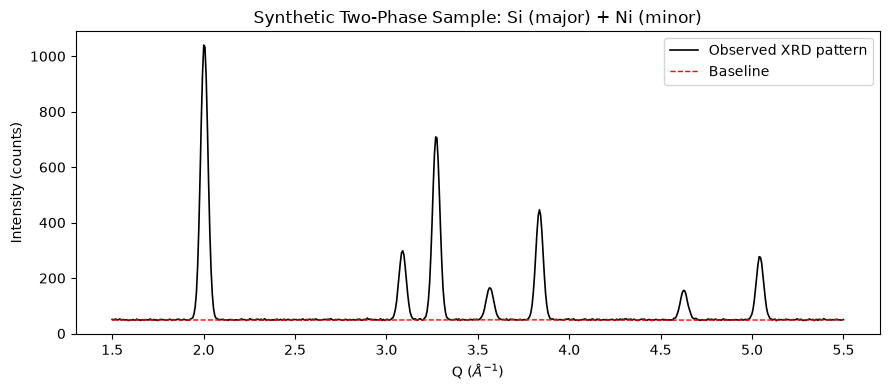

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pymatgen.core.lattice import Lattice
from pymatgen.core.structure import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from easyxrd import exrd

# 1. Define reference structures
si = Structure.from_spacegroup("Fd-3m", Lattice.cubic(5.431), ["Si"], [[0, 0, 0]])
ni = Structure.from_spacegroup("Fm-3m", Lattice.cubic(3.524), ["Ni"], [[0, 0, 0]])
au = Structure.from_spacegroup("Fm-3m", Lattice.cubic(4.078), ["Au"], [[0, 0, 0]])  # Candidate not present in sample

# 2. Synthesize 1D XRD pattern (Cu Ka, lambda = 1.5406 A)
wavelength = 1.5406
xrdc = XRDCalculator(wavelength=wavelength)
q = np.linspace(1.5, 5.5, 600)

# Baseline + Gaussian noise
np.random.seed(42)
y = 50.0 + np.random.normal(0, 1.5, size=q.shape)

# Add Silicon peaks (major)
pat_si = xrdc.get_pattern(si, scaled=True, two_theta_range=(10.0, 90.0))
q_si = 4.0 * np.pi * np.sin(np.deg2rad(pat_si.x / 2.0)) / wavelength
for qp, yp in zip(q_si, pat_si.y):
    if 1.5 <= qp <= 5.5:
        y += 10.0 * yp * np.exp(-0.5 * ((q - qp) / 0.02) ** 2)

# Add Nickel peaks (minor)
pat_ni = xrdc.get_pattern(ni, scaled=True, two_theta_range=(10.0, 90.0))
q_ni = 4.0 * np.pi * np.sin(np.deg2rad(pat_ni.x / 2.0)) / wavelength
for qp, yp in zip(q_ni, pat_ni.y):
    if 1.5 <= qp <= 5.5:
        y += 2.5 * yp * np.exp(-0.5 * ((q - qp) / 0.02) ** 2)

# 3. Load data into easyXRD and estimate baseline
x = exrd()
x.load_xrd_data(
    from_i1d_array=np.column_stack([q, y]),
    i1d_array_radial_unit="q",
    i1d_array_wavelength_in_angstrom=wavelength,
    plot=False,
)
x.get_baseline(plot=False)

plt.figure(figsize=(9, 4))
plt.plot(q, y, 'k-', lw=1.2, label="Observed XRD pattern")
plt.plot(q, x.ds.i1d_baseline, 'r--', lw=1.0, label="Baseline")
plt.xlabel("Q ($Å^{-1}$)")
plt.ylabel("Intensity (counts)")
plt.title("Synthetic Two-Phase Sample: Si (major) + Ni (minor)")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Screen Against Local Candidate Structures

Suppose our candidate pool contains `Si`, `Ni`, and `Au`. We pass them as a dictionary of `pymatgen.Structure` objects (or paths to `.cif` files) to `screen_phases()`.

In [2]:
candidates = {
    "Silicon": si,
    "Nickel": ni,
    "Gold": au,
}

# Screen candidates against observed peaks
ranked = x.screen_phases(
    candidate_structures=candidates,
    tolerance_q=0.04,        # Q tolerance window for peak matching (in Å^-1)
    peak_prominence=0.03,    # Peak detection prominence threshold
)

print(f"{'Rank':<5} {'Candidate':<10} {'Formula':<10} {'SpaceGroup':<12} {'Match Score':<12} {'FOM':<8} {'Matched Peaks'}")
print("-" * 75)
for idx, cand in enumerate(ranked, start=1):
    print(f"{idx:<5} {cand['label']:<10} {cand['formula']:<10} {cand['space_group']:<12} "
          f"{cand['match_score']:<12.1f} {cand['fom']:<8.3f} "
          f"{cand['matched_peaks']}/{cand['total_candidate_peaks']}")

Rank  Candidate  Formula    SpaceGroup   Match Score  FOM      Matched Peaks
---------------------------------------------------------------------------
1     Silicon    Si         Fd-3m        92.9         0.929    5/5
2     Nickel     Ni         Fm-3m        75.7         0.757    3/3
3     Gold       Au         Fm-3m        71.3         0.713    5/5


Notice that **Silicon** and **Nickel** correctly receive top scores while **Gold** receives a low/zero score because its Bragg reflections do not match the experimental peak positions.

## 3. Query and Screen via Materials Project (`chemsys`)

If you don't have local CIF files, you can query all stable and near-stable phases in a chemical system directly from the **Materials Project** database by setting `chemsys`.

> **Note:** Requires a Materials Project API key, either passed via `mp_rester_api_key="..."` or exported as the environment variable `MP_API_KEY`.

In [3]:
# Example usage with Materials Project:
# mp_candidates = x.screen_phases(
#     chemsys="Si-Ni",             # Automatically checks Si, Ni, and Si-Ni binaries
#     e_above_hull_max=0.05,       # Restrict to stable or near-stable compounds (<= 50 meV/atom)
#     max_candidates=5,            # Return top 5 matches
#     tolerance_q=0.03,
#     mp_rester_api_key=None,      # Reads from MP_API_KEY environment variable
# )
#
# for cand in mp_candidates:
#     print(f"{cand['label']} (MP ID: {cand['mp_id']}): FOM = {cand['fom']:.3f}")

## 4. Screening Residual Intensity (`use_residual=True`)

In multi-phase samples, major phases often dwarf minor impurities. A standard workflow is:
1. Fit and refine the major phase (`Silicon`).
2. Inspect the unmodeled residual $\Delta Y = Y_{\text{obs}} - Y_{\text{calc}}$.
3. Call `screen_phases(use_residual=True)` to identify what constitutes the leftover misfit peaks.

In [4]:
# 1. Load Silicon as the only known phase
x.load_phases(from_phases_dict=[{"label": "Si", "structure": si}], plot=False)

# 2. Setup GSAS-II refiner and refine Silicon
x.setup_gsas2_refiner(plot=False)
x.set_LeBail(False, plot=False)
x.refine_cell_parameters(report=False, plot=False)

# 3. Screen remaining candidates against the unindexed RESIDUAL peaks
residual_matches = x.screen_phases(
    candidate_structures={"Nickel": ni, "Gold": au},
    use_residual=True,         # Focuses search on (Y_obs - Y_calc)
    tolerance_q=0.04,
)

print("Residual screening results:")
for cand in residual_matches:
    print(f"  Phase: {cand['label']:<8} FOM: {cand['fom']:.3f} "
          f"Matched: {cand['matched_peaks']}/{cand['total_candidate_peaks']} peaks")

GSAS-II binaries co-located with GSAS-II: /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII
5 values read from /home/mt/.GSASII/config.ini


/home/mt/mpixi/easyXRD/easyxrd/refinement.py:1030: UserWarning: No measurement variance supplied: using unit weights; GoF and uncertainties lack a counting-statistics interpretation
  warnings.warn("No measurement variance supplied: using unit weights; GoF and uncertainties lack a counting-statistics interpretation", UserWarning)


 ✅--1st refinement with LeBail is completed. Rwp/GoF is 79.510/98.923
 ✅--After setting LeBail refinement to False, Rwp/GoF is now 79.510/98.923 (was 79.510(0.00%)/98.923(0.00%!))
 ✅--Cell parameters are refined. Rwp/GoF is now 78.810/98.135 (was 79.510(-0.88%)/98.923(-0.80%!))
Residual screening results:
  Phase: Nickel   FOM: 0.742 Matched: 3/3 peaks
  Phase: Gold     FOM: 0.164 Matched: 1/5 peaks


## 5. Direct Handoff into Two-Phase Rietveld Refinement

Top candidates returned by `screen_phases()` contain full pymatgen `Structure` objects in `cand['structure']`. We can load the identified candidate directly and refine both phases simultaneously.

/home/mt/mpixi/easyXRD/easyxrd/refinement.py:1030: UserWarning: No measurement variance supplied: using unit weights; GoF and uncertainties lack a counting-statistics interpretation
  warnings.warn("No measurement variance supplied: using unit weights; GoF and uncertainties lack a counting-statistics interpretation", UserWarning)


 ✅--1st refinement with LeBail is completed. Rwp/GoF is now 89.469/111.314 (was 79.510(12.53%)/98.923(12.53%!))
 ✅--After setting LeBail refinement to False, Rwp/GoF is now 89.469/111.314 (was 89.469(0.00%)/111.314(0.00%!))
 ✅--Cell parameters of all phases are refined. Rwp/GoF is now 87.867/109.503 (was 89.469(-1.79%)/111.314(-1.63%))
 ✅--Phase fractions of all phases are refined. Rwp/GoF is now 77.558/96.575 (was 87.867(-11.73%)/109.503(-11.81%*))


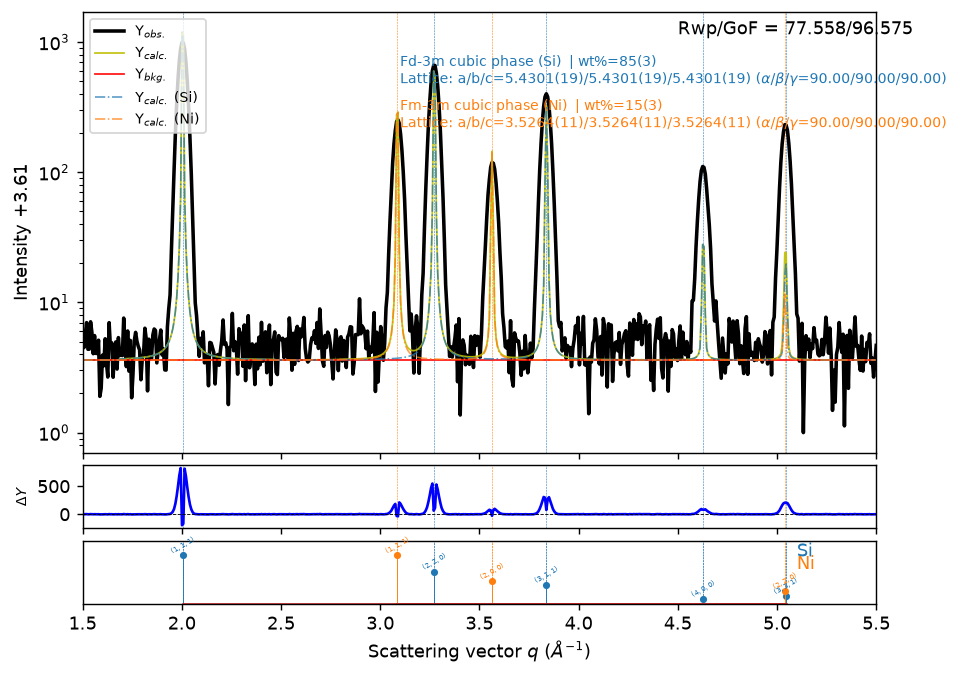

In [5]:
# Load both identified phases
x.load_phases(
    from_phases_dict=[
        {"label": "Si", "structure": si},
        {"label": "Ni", "structure": residual_matches[0]["structure"]},
    ],
    plot=False,
)

# Run full quantitative Rietveld refinement
x.setup_gsas2_refiner(plot=False)
x.set_LeBail(False, plot=False)
x.refine_cell_parameters(report=True, plot=False)
x.refine_phase_fractions(plot=False)

# Display plot with individual deconvolved phase profiles and normalized residuals
x.plot(
    show_phase_profiles=True,      # Plots deconvolved Y_calc for Si and Ni
    normalized_residuals=True,     # Shows Delta / sigma in the residual panel
    show_wt_fractions=True,
    close=False,
)
plt.show()